# Market Basket Analysis

### 1. Data Preprocessing

In [37]:
# Mengimpor library yang diperlukan
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

In [38]:
# Mengimpor dataset sehingga dapat digunakan
df_master = pd.read_csv('groceries_dataset.csv')
df_before = df_master.copy()
df = df_master.copy()

In [39]:
# Menampilkan data
df.head(10)

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
5,4941,14-02-2015,rolls/buns
6,4501,08-05-2015,other vegetables
7,3803,23-12-2015,pot plants
8,2762,20-03-2015,whole milk
9,4119,12-02-2015,tropical fruit


#### Deskripsi Dataset

Dataset ini berisi riwayat transaksi pembelian produk point of sales di sebuah groceries store. Setiap baris data merepresentasikan satu unit item yang dibeli oleh pelanggan pada tanggal tertentu.

**Deskripsi Fitur / Kolom:**
- **Member_number**   : Nomor identitas unik pelanggan (*Customer/Member ID*) yang terdaftar dan melakukan pembelian.
- **Date**            : Tanggal transaksi pembelian dilakukan oleh pelanggan (dalam format DD-MM-YYYY).
- **itemDescription** : Nama atau deskripsi produk kebutuhan sehari-hari (*groceries*) yang dibeli pelanggan.

In [40]:
# Menampilkan dimensi dataset dan menjelaskan jumlah baris/kolom
print("Dimensi Dataset :", df.shape[0], "rows x", df.shape[1], "columns")

Dimensi Dataset : 38765 rows x 3 columns


In [41]:
# Menampilkan dan menjelaskan  informasi
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB


**Temuan dari Informasi Dataset**

- **Jumlah Data & Kolom** : Dataset memiliki **38.765 baris** dan **3 kolom**.
- **Kelengkapan Data (Missing Value)** : Seluruh kolom memiliki nilai non-null penuh (**38.765 non-null**), artinya **tidak ada nilai kosong/hilang (missing value)** yang terdeteksi.
- **Kesesuaian Tipe Data** :
  - Member_number awalnya bertipe **int64** (integer). Kolom ini merupakan nomor identitas unik pelanggan (*identifier*), sehingga perlu dikonversi ke tipe data **string/object** agar tidak diperlakukan sebagai variabel matematika kuantitatif.
  - Date saat ini bertipe **object** (string/teks). Kolom ini perlu dikonversi ke tipe data **datetime** untuk analisis pola waktu dan runtun transaksi.
  - itemDescription bertipe **object** (string/teks), berisi nama-nama item barang belanjaan.

### Konversi Tipe Data

In [42]:
# Mengidentifikasi dan menjelaskan tipe data setiap kolom
df.dtypes

Member_number       int64
Date               object
itemDescription    object
dtype: object

In [43]:
# Konversi Tipe Data Date ke datetime dan Member_number ke string
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df['Member_number'] = df['Member_number'].astype(str)
print('Tipe data df[Date]          = ', df['Date'].dtypes)
print('Tipe data df[Member_number] = ', df['Member_number'].dtypes)

Tipe data df[Date]          =  datetime64[ns]
Tipe data df[Member_number] =  object


#### Pengecekan Missing Value

In [44]:
# Mengecek jumlah dan persentase missing value
(df.isnull().sum()).to_frame(name='Jumlah Missing Value')

,Jumlah Missing Value
Member_number,0
Date,0
itemDescription,0


In [45]:
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Member_number,0.0
Date,0.0
itemDescription,0.0


#### Pengecekan Konsistensi Data

In [46]:
# Mengecek Konsistensi Teks (itemDescription)

# Cek spasi di awal atau akhir kata (leading/trailing whitespace)
trailing_spaces = [item for item in df['itemDescription'].unique() if item != item.strip()]
print(f"Item dengan spasi di awal/akhir                        : {trailing_spaces}")

# Cek konsistensi huruf kapital (apakah ada item yang sama tapi beda huruf besar/kecil)
items = df['itemDescription'].unique()
items_lower = {}
case_inconsistencies = []
for item in items:
    cleaned = item.lower().strip()
    if cleaned in items_lower and items_lower[cleaned] != item:
        case_inconsistencies.append((items_lower[cleaned], item))
    else:
        items_lower[cleaned] = item

print(f"Inkonsistensi Casing (duplikat beda huruf besar/kecil) : {len(case_inconsistencies)}")

# c. Cek nilai placeholder aneh (seperti '?', '-', 'null', 'none')
weird_values = df[df['itemDescription'].str.lower().isin(['?', '-', 'null', 'nan', 'none', 'unknown'])]
print(f"Jumlah nilai placeholder/aneh                          : {len(weird_values)}")

Item dengan spasi di awal/akhir                        : ['cream cheese ', 'roll products ']
Inkonsistensi Casing (duplikat beda huruf besar/kecil) : 0
Jumlah nilai placeholder/aneh                          : 0


Terdapat 2 item yang memiliki spasi di akhir kata (trailing space):
- 'cream cheese ' (358 baris)
- 'roll products ' (82 baris)

In [47]:
# Menghapus spasi di awal/akhir dan mengubah ke huruf kecil agar konsisten
df['itemDescription'] = df['itemDescription'].str.strip().str.lower()
print("Spasi tersembunyi berhasil dibersihkan!")

Spasi tersembunyi berhasil dibersihkan!


In [48]:
inkonsistensi = df.select_dtypes(include=["object"]).columns

for i in inkonsistensi:
    print(f"Kolom {i} :")
    print(df[i].unique())
    print("\n")

Kolom Member_number :
['1808' '2552' '2300' ... '3607' '4587' '2417']


Kolom itemDescription :
['tropical fruit' 'whole milk' 'pip fruit' 'other vegetables' 'rolls/buns'
 'pot plants' 'citrus fruit' 'beef' 'frankfurter' 'chicken' 'butter'
 'fruit/vegetable juice' 'packaged fruit/vegetables' 'chocolate'
 'specialty bar' 'butter milk' 'bottled water' 'yogurt' 'sausage'
 'brown bread' 'hamburger meat' 'root vegetables' 'pork' 'pastry'
 'canned beer' 'berries' 'coffee' 'misc. beverages' 'ham' 'turkey'
 'curd cheese' 'red/blush wine' 'frozen potato products' 'flour' 'sugar'
 'frozen meals' 'herbs' 'soda' 'detergent' 'grapes' 'processed cheese'
 'fish' 'sparkling wine' 'newspapers' 'curd' 'pasta' 'popcorn'
 'finished products' 'beverages' 'bottled beer' 'dessert' 'dog food'
 'specialty chocolate' 'condensed milk' 'cleaner' 'white wine' 'meat'
 'ice cream' 'hard cheese' 'cream cheese' 'liquor' 'pickled vegetables'
 'liquor (appetizer)' 'uht-milk' 'candy' 'onions' 'hair spray'
 'photo/film' '

Insight Pemeriksaan Nilai Unik & Konsistensi Teks:
- **Bebas Kesalahan Ketik (*Typo*):** Berdasarkan hasil inspeksi pada seluruh nilai unik kolom itemDescription, tidak ditemukan adanya kesalahan penulisan (*typo*), singkatan tidak baku, maupun karakter asing/aneh (seperti simbol `?`, `-`, atau `null`).
- **Kategori Produk Baku:** Seluruh 167 nama item belanjaan merupakan nama produk standar industri ritel yang sudah konsisten (*clean*) dan siap digunakan untuk analisis asosiasi.


In [49]:
# Mengecek Konsistensi  Tanggal (Date)
converted_dates = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
invalid_dates = converted_dates.isna().sum()
print(f"Jumlah tanggal tidak valid  : {invalid_dates}")

print(f"Rentang tanggal             : {converted_dates.min().strftime('%d-%m-%Y')} s/d {converted_dates.max().strftime('%d-%m-%Y')}")

Jumlah tanggal tidak valid  : 0
Rentang tanggal             : 01-01-2014 s/d 30-12-2015


#### Pembersihan Duplikat

In [50]:
# Mengecek jumlah dan persentase data duplikat
print("Jumlah Data Duplikat :", df.duplicated().sum())

Jumlah Data Duplikat : 759


In [51]:
print("Persentase Data Duplikat :", (df.duplicated().sum()/len(df))*100, "%")

Persentase Data Duplikat : 1.9579517606087966 %


In [52]:
# Menghapus baris duplikat
print("Jumlah baris sebelum drop duplikat:", df.shape[0])
df = df.drop_duplicates()
print("Jumlah baris setelah drop duplikat:", df.shape[0])

Jumlah baris sebelum drop duplikat: 38765


Jumlah baris setelah drop duplikat: 38006


**Insight & Alasan Drop Duplikat:**
- Terdapat **759 data duplikat** yang menunjukkan pelanggan membeli item yang sama lebih dari satu unit dalam satu transaksi/hari yang sama.
- Data duplikat di-*drop* karena **Market Basket Analysis (MBA)** berfokus pada **keberadaan produk dalam keranjang (biner: ada / tidak ada)**, bukan pada jumlah kuantitas unit yang dibeli.
- Menghapus duplikasi memastikan setiap produk hanya dihitung satu kali per transaksi dan mencegah timbulnya aturan asosiasi semu (*self-association*).


#### Statistika Deskriptif Dataset

In [53]:
# Menampilkan dan menjelaskan  statistika deskriptif dataset
df.describe()

,Date
count,38006
mean,2015-01-08 22:17:51.115087104
min,2014-01-01 00:00:00
25%,2014-07-12 00:00:00
50%,2015-01-19 00:00:00
75%,2015-07-09 00:00:00
max,2015-12-30 00:00:00


In [54]:
df['itemDescription'].describe()

count          38006
unique           167
top       whole milk
freq            2363
Name: itemDescription, dtype: object

In [55]:
df['Member_number'].describe()

count     38006
unique     3898
top        3180
freq         35
Name: Member_number, dtype: object

Interpretasi Statistika Deskriptif:

1. **Kolom Waktu (df.describe()):**
   - **Date:** Transaksi tercatat aktif selama **2 tahun penuh** (1 Januari 2014 s/d 30 Desember 2015) dengan median tanggal 19 Januari 2015. Data historis ini sangat memadai untuk melihat pola belanja harian, mingguan, maupun musiman.
2. **Kolom Kategorikal (df['itemDescription'].describe() & df['Member_number'].describe()):**
   - **Variasi Produk (itemDescription):** Terdapat **167 jenis produk unik** dari total 38.006 baris transaksi. Produk yang paling sering dibeli adalah **whole milk** dengan frekuensi kemunculan sebanyak **2.363 kali** (~15,8% dari total transaksi).
   - **Pelanggan (Member_number):** Terdapat **3.898 pelanggan unik** yang berbelanja. Pelanggan paling aktif adalah member dengan ID **3180** yang tercatat melakukan pembelian 35 kali/item.

#### Feature Engineering (Penambahan Kolom Baru)

In [56]:
# Menambahkan Transaction_ID
df['Transaction_ID'] = df['Member_number'].astype(str) + '_' + df['Date'].dt.strftime('%d-%m-%Y')
print(f"Total transaksi/keranjang unik: {df['Transaction_ID'].nunique()}")

# Menghitung jumlah item riil per transaksi (Kuantitas Objektif)
df['Basket_Size'] = df.groupby('Transaction_ID')['itemDescription'].transform('count')

# Ekstraksi Waktu
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day_Name'] = df['Date'].dt.day_name()

# Menampilkan 5 baris pertama data hasil pembaruan
print(f"Dataset berhasil diperbarui. Dimensi data: {df.shape[0]} baris x {df.shape[1]} kolom.")
df[['Transaction_ID', 'Member_number', 'Date', 'Day_Name', 'Month', 'Year', 'itemDescription', 'Basket_Size']].head()

Total transaksi/keranjang unik: 14963
Dataset berhasil diperbarui. Dimensi data: 38006 baris x 8 kolom.


,Transaction_ID,Member_number,Date,Day_Name,Month,Year,itemDescription,Basket_Size
0,1808_21-07-2015,1808,2015-07-21,Tuesday,7,2015,tropical fruit,3
1,2552_05-01-2015,2552,2015-01-05,Monday,1,2015,whole milk,3
2,2300_19-09-2015,2300,2015-09-19,Saturday,9,2015,pip fruit,3
3,1187_12-12-2015,1187,2015-12-12,Saturday,12,2015,other vegetables,3
4,3037_01-02-2015,3037,2015-02-01,Sunday,2,2015,whole milk,3


Fitur-fitur baru dibuat untuk menjembatani keterbatasan data mentah agar siap diproses oleh algoritma *Market Basket Analysis* dan analisis tren bisnis:

1. Transaction_ID (Member_number + Date):
   - **Alasan:** Dataset kasir ini tidak memiliki nomor struk belanja (receipt/invoice number). 
   - **Fungsi:** Mengelompokkan seluruh barang yang dibeli oleh **pelanggan yang sama pada tanggal yang sama** ke dalam satu identitas keranjang belanja (*market basket*) yang valid untuk analisis asosiasi produk.

2. Basket_Size (Ukuran Keranjang):
   - **Alasan:** Mengukur total ragam produk berbeda yang dibeli dalam satu kali transaksi.
   - **Fungsi:** Mengetahui perilaku kuantitas belanja konsumen, mengidentifikasi transaksi janggal (*outlier*), serta menjadi dasar jika ingin menyaring transaksi satu barang (*single-item transactions*).

3. Fitur Waktu (Day_Name, Month, Year):
   - **Alasan:** Mengekstrak komponen tanggal menjadi dimensi waktu yang lebih terperinci.
   - **Fungsi:** Memungkinkan analisis pola perilaku belanja musiman.

### Pengecekan Outlier
* Ukuran Keranjang (*Basket Size*): Berapa banyak macam barang yang ditaruh pembeli di meja kasir dalam **sekali bayar**?  
  
  **Contoh:** Kalau pelanggan ke kasir cuma bawa susu dan roti, berarti ukuran keranjang Anda = **2 barang**.
* Frekuensi Member (*Member Frequency*): Berapa kali seorang pelanggan **datang berbelanja** ke toko ini  
  
  **Contoh:** Pelanggan A datang belanja 3 kali dalam 2 tahun, berarti frekuensinya = **3 kali**. (dalam kontek projek ini, waktu yang dimaksud berarti berapa kali dia beli di dataset)

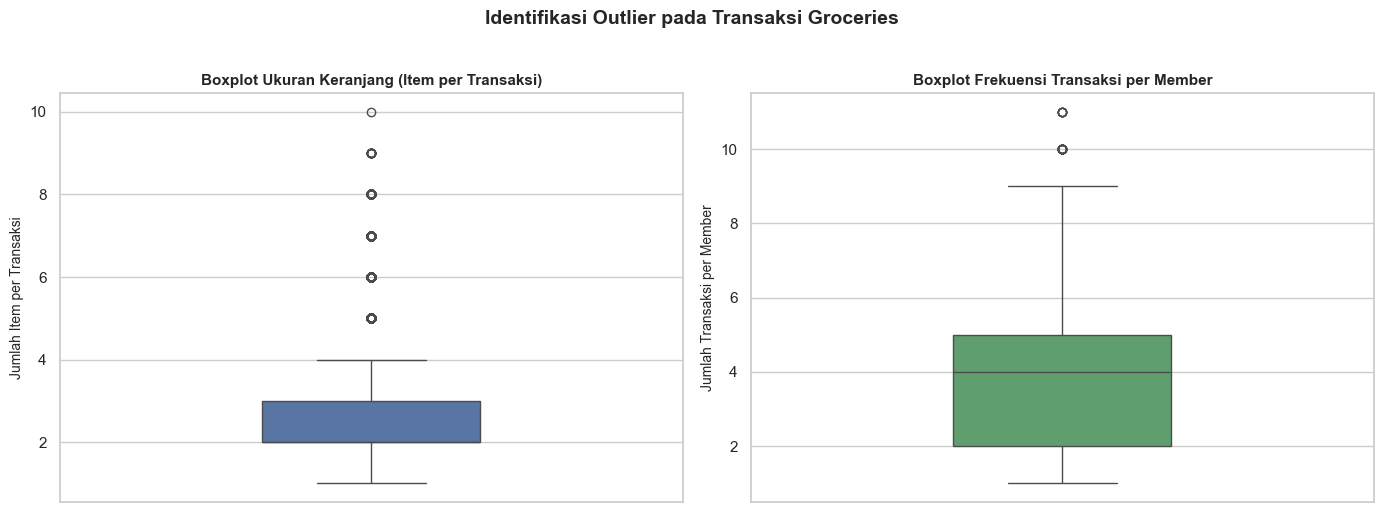

In [57]:
# Menghitung jumlah item per transaksi (Basket Size)
basket_size = df.groupby('Transaction_ID')['itemDescription'].count().reset_index()
basket_size.rename(columns={'itemDescription': 'Item_Count'}, inplace=True)

# Menghitung jumlah transaksi per member
member_frequency = df.groupby('Member_number')['Transaction_ID'].nunique().reset_index()
member_frequency.rename(columns={'Transaction_ID': 'Transaction_Count'}, inplace=True)

# Visualisasi Boxplot Berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot Ukuran Keranjang
sns.boxplot(ax=axes[0], y=basket_size['Item_Count'], color='#4C72B0', width=0.35)
axes[0].set_title('Boxplot Ukuran Keranjang (Item per Transaksi)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Jumlah Item per Transaksi', fontsize=10)

# Boxplot Frekuensi Member
sns.boxplot(ax=axes[1], y=member_frequency['Transaction_Count'], color='#55A868', width=0.35)
axes[1].set_title('Boxplot Frekuensi Transaksi per Member', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Jumlah Transaksi per Member', fontsize=10)

plt.suptitle('Identifikasi Outlier pada Transaksi Groceries', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Insight Boxplot Ukuran Keranjang (*Basket Size*) & Frekuensi Member:
1. Ukuran Keranjang (*Basket Size*):
   - Mayoritas keranjang belanja berukuran kecil, yaitu 2 – 3 item per transaksi.
   - Titik-titik **outlier** terdeteksi pada transaksi dengan **$\ge 5$ item**. Outlier ini **tetap dipertahankan** karena mencerminkan variasi belanja wajar (belanja mingguan/bulanan konsumen), bukan error pencatatan sistem.
2. Frekuensi Transaksi Member:
   - Mayoritas pelanggan melakukan **2 hingga 5 kali transaksi** selama 2 tahun (2014 – 2015).
   - Terdapat sejumlah pelanggan dengan frekuensi hingga 10 – 11 kunjungan yang mencerminkan segmen pelanggan setia (*loyal customers*).


#### Rangkuman Hasil Data Preprocessing

In [58]:
# Menghitung metrik ringkasan
total_duplikat_dihapus = df_before.duplicated().sum() - df.duplicated().sum()
persen_duplikat = (total_duplikat_dihapus / len(df_before)) * 100

summary_data = {
    'Indikator / Metrik': [
        'Dimensi Data (Baris x Kolom)',
        'Missing Value',
        'Baris Duplikat',
        'Tipe Data Kolom Date',
        'Jumlah Produk Unik (itemDescription)',
        'Jumlah Pelanggan Unik (Member_number)',
        'Jumlah Keranjang Unik (Transaction_ID)',
        'Rentang Periode Transaksi',
        'Outlier ID Pelanggan (Member_number)',
        'Outlier Ukuran Keranjang (Basket Size)',
        'Status Kesiapan Data'
    ],
    'Sebelum Preprocessing (df_before)': [
        f"{df_before.shape[0]:,} baris x {df_before.shape[1]} kolom",
        f"{df_before.isnull().sum().sum()} nilai kosong",
        f"{df_before.duplicated().sum():,} baris duplikat",
        f"{df_before['Date'].dtype} (string)",
        f"{df_before['itemDescription'].nunique()} item (ada trailing space)",
        f"{df_before['Member_number'].nunique():,} pelanggan",
        "Belum tersedia (tidak ada ID keranjang)",
        "01-01-2014 s/d 30-12-2015",
        "Belum dianalisis",
        "Belum dianalisis",
        "Data Mentah (Raw)"
    ],
    'Setelah Preprocessing (df)': [
        f"{df.shape[0]:,} baris x {df.shape[1]} kolom",
        f"{df.isnull().sum().sum()} nilai kosong (100% lengkap)",
        f"{df.duplicated().sum()} baris ({total_duplikat_dihapus:,} baris / {persen_duplikat:.2f}% dibersihkan)",
        f"{df['Date'].dtype} (format waktu baku)",
        f"{df['itemDescription'].nunique()} item (bersih, konsisten, lowercase)",
        f"{df['Member_number'].nunique():,} pelanggan (ID 1000 - 5000 valid)",
        f"{df['Transaction_ID'].nunique():,} transaksi/keranjang unik",
        f"{df['Date'].min().strftime('%d-%m-%Y')} s/d {df['Date'].max().strftime('%d-%m-%Y')}",
        "0 Outlier (semua ID wajar & seragam)",
        "Outlier terdeteksi (>= 5 item, dipertahankan)",
        "Cleaned & Siap untuk Tahap EDA"
    ]
}
df_summary = pd.DataFrame(summary_data)
pd.set_option('display.max_colwidth', None)
df_summary

,Indikator / Metrik,Sebelum Preprocessing (df_before),Setelah Preprocessing (df)
0,Dimensi Data (Baris x Kolom),"38,765 baris x 3 kolom","38,006 baris x 8 kolom"
1,Missing Value,0 nilai kosong,0 nilai kosong (100% lengkap)
2,Baris Duplikat,759 baris duplikat,0 baris (759 baris / 1.96% dibersihkan)
3,Tipe Data Kolom Date,object (string),datetime64[ns] (format waktu baku)
4,Jumlah Produk Unik (itemDescription),167 item (ada trailing space),"167 item (bersih, konsisten, lowercase)"
5,Jumlah Pelanggan Unik (Member_number),"3,898 pelanggan","3,898 pelanggan (ID 1000 - 5000 valid)"
6,Jumlah Keranjang Unik (Transaction_ID),Belum tersedia (tidak ada ID keranjang),"14,963 transaksi/keranjang unik"
7,Rentang Periode Transaksi,01-01-2014 s/d 30-12-2015,01-01-2014 s/d 30-12-2015
8,Outlier ID Pelanggan (Member_number),Belum dianalisis,0 Outlier (semua ID wajar & seragam)
9,Outlier Ukuran Keranjang (Basket Size),Belum dianalisis,"Outlier terdeteksi (>= 5 item, dipertahankan)"


### 2. Exploratory Data Analysis (EDA)

#### Uji Distribusi & Normalitas Data

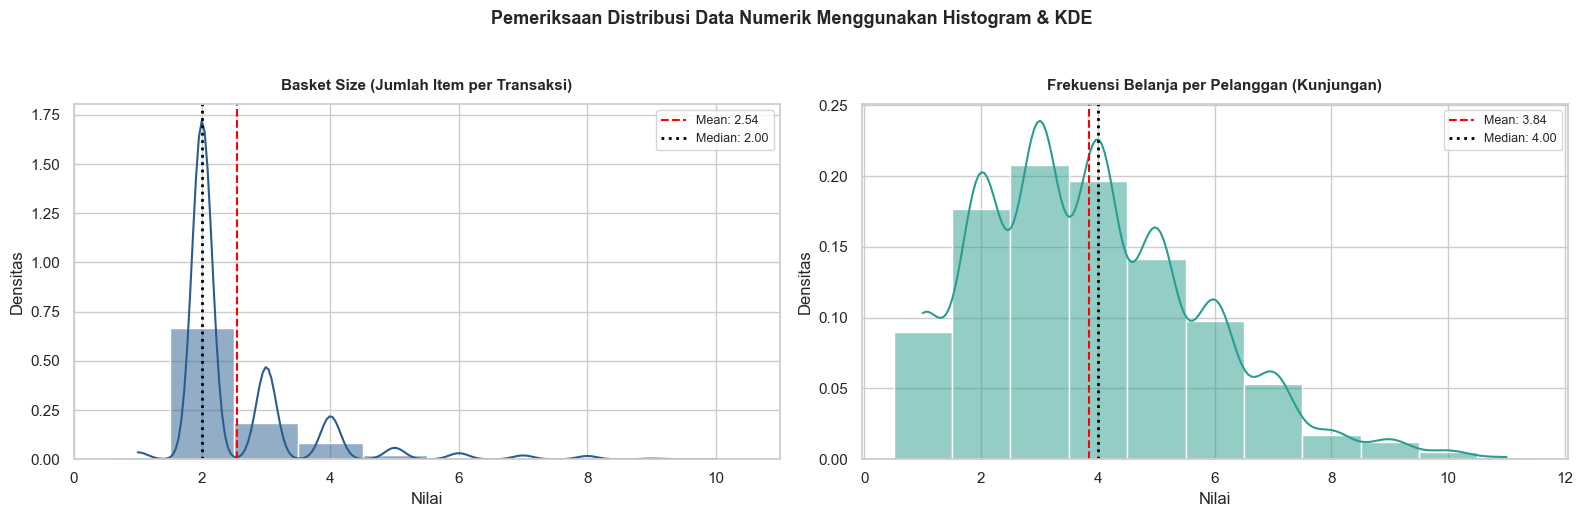

In [59]:
# Menyiapkan data numerik yang dianalisis
basket_size = df.drop_duplicates('Transaction_ID')['Basket_Size']
member_frequency = df.groupby('Member_number')['Transaction_ID'].nunique()

features_dict = {
    'Basket Size (Jumlah Item per Transaksi)': basket_size,
    'Frekuensi Belanja per Pelanggan (Kunjungan)': member_frequency
}

# Visualisasi Histogram + KDE
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for i, (title, series) in enumerate(features_dict.items()):
    ax = axes[i]
    
    # Keduanya data diskrit diskret
    sns.histplot(series, kde=True, ax=ax, stat="density", discrete=True, color='#2b5c8f' if i==0 else '#2a9d8f')
    
    # Garis vertikal Mean & Median
    mean_val = series.mean()
    median_val = series.median()
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_val:.2f}')
    ax.axvline(median_val, color='black', linestyle=':', linewidth=2, label=f'Median: {median_val:.2f}')
    
    ax.set_title(title, fontsize=11, fontweight='bold', pad=10)
    ax.set_xlabel('Nilai')
    ax.set_ylabel('Densitas')
    ax.legend(fontsize=9)

plt.suptitle('Pemeriksaan Distribusi Data Numerik Menggunakan Histogram & KDE', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [60]:
# UJI NORMALITAS STATISTIK (D'AGOSTINO-PEARSON TEST)
normality_results = []

for title, series in features_dict.items():
    skew_val = series.skew()
    kurt_val = series.kurtosis()
    stat_val, p_val = stats.normaltest(series)
    
    normality_results.append({
        'Variabel': title,
        'Mean': round(series.mean(), 2),
        'Median': round(series.median(), 2),
        'Skewness': round(skew_val, 2),
        'Kurtosis': round(kurt_val, 2),
        'P-Value': f"{p_val:.4e}",
        'Status Normalitas': 'Normal (p > 0.05)' if p_val > 0.05 else 'Tidak Normal (p <= 0.05)'
    })

df_normality = pd.DataFrame(normality_results)
df_normality

,Variabel,Mean,Median,Skewness,Kurtosis,P-Value,Status Normalitas
0,Basket Size (Jumlah Item per Transaksi),2.54,2.0,2.55,8.19,0.0000e+00,Tidak Normal (p <= 0.05)
1,Frekuensi Belanja per Pelanggan (Kunjungan),3.84,4.0,0.64,0.24,1.3568e-51,Tidak Normal (p <= 0.05)


Interpretasi Uji Distribusi & Normalitas Data

Berdasarkan visualisasi Histogram & KDE serta uji statistik **D'Agostino-Pearson** (signifikansi $\alpha = 0,05$), diperoleh kesimpulan objektif terhadap 2 variabel numerik perilaku belanja konsumen:

1. **Basket Size (Jumlah Item per Transaksi):**
   - **Parameter Statistik:** Mean = **2,54 item**, Median = **2,00 item**, Skewness = **2,55**, Kurtosis = **8,19** ($p\text{-value} = 0.0000$).
   - **Karakteristik Distribusi:** **Sangat Miring ke Kanan (Strongly Right-Skewed)** dan **Tidak Berdistribusi Normal**. Mayoritas transaksi berukuran kecil (2–3 barang), dengan sebagian kecil keranjang belanja besar ($\ge 5$ barang).

2. **Frekuensi Belanja per Pelanggan (Jumlah Kunjungan/Transaksi):**
   - **Parameter Statistik:** Mean = **3,84 kali**, Median = **4,00 kali**, Skewness = **0,64**, Kurtosis = **0,24** ($p\text{-value} = 1.36 \times 10^{-51}$).
   - **Karakteristik Distribusi:** **Miring ke Kanan (Moderately Right-Skewed)** dan **Tidak Berdistribusi Normal**. Mayoritas pelanggan melakukan 2 hingga 5 kali transaksi selama 2 tahun pengamatan.

Relevansi & Implikasi terhadap Market Basket Analysis (MBA):

* **Sifat Algoritma Non-Parametrik:** Algoritma *Association Rule Mining* (seperti **Apriori**) **TIDAK mensyaratkan data berdistribusi normal**. Algoritma ini murni bekerja menghitung frekuensi kemunculan bersama (*co-occurrence count*) antar-kombinasi produk secara biner, bukan estimasi parameter regresi/varian populasi.
* **Fenomena Alami Ritel:** Pola distribusi keranjang belanja dan frekuensi kunjungan yang miring ke kanan (*right-skewed*) adalah karakteristik alami industri ritel groceries: mayoritas konsumen berbelanja cepat untuk kebutuhan harian, sementara sebagian kecil pelanggan melakukan belanja besar atau tergolong pelanggan setia (*loyal repeat customers*).

#### Top 10 Produk Terpopuler

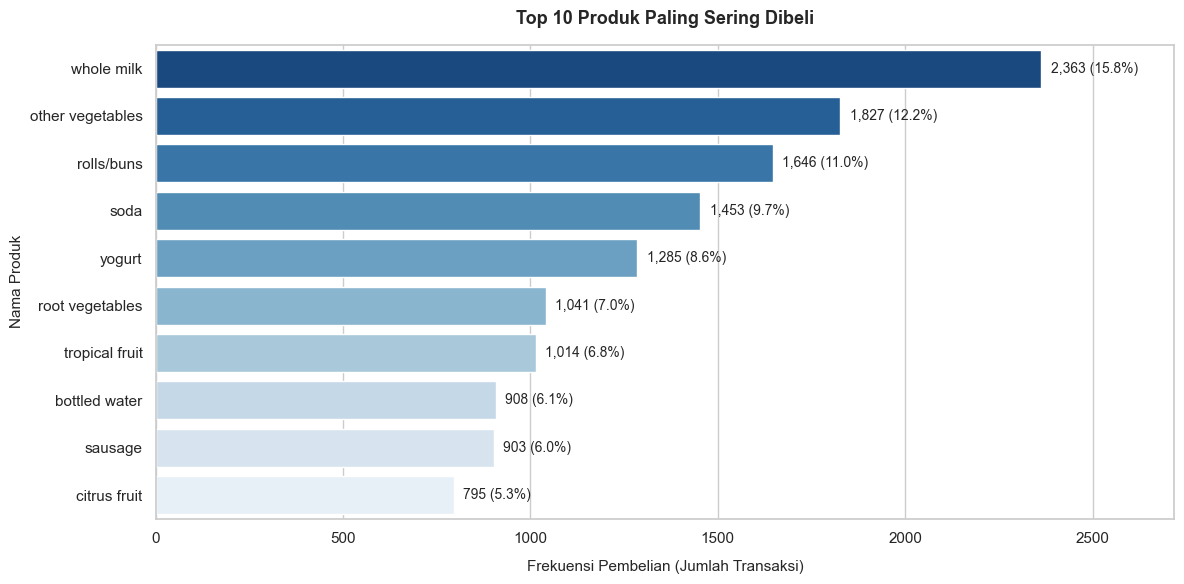

In [61]:
# Visualisasi Top 10 Produk Terpopuler
top_10_items = df['itemDescription'].value_counts().head(10).reset_index()
top_10_items.columns = ['Product', 'Frequency']

# Menghitung persentase terhadap total transaksi (Penetrasi / Support riil)
total_transactions = df['Transaction_ID'].nunique()
top_10_items['Transaction_Pct'] = (top_10_items['Frequency'] / total_transactions) * 100

# Plotting Horizontal Bar Chart
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Warna gradient / palette modern
palette = sns.color_palette("Blues_r", n_colors=10)

# Tambahkan hue='Product' dan legend=False untuk menghilangkan warning
ax = sns.barplot(
    data=top_10_items, 
    x='Frequency', 
    y='Product', 
    hue='Product', 
    palette=palette, 
    legend=False
)

# Menambahkan data label (Jumlah Frekuensi & % Penetrasi Transaksi) pada setiap bar
for p, pct in zip(ax.patches, top_10_items['Transaction_Pct']):
    width = p.get_width()
    ax.annotate(f"{int(width):,} ({pct:.1f}%)",
                (width + 25, p.get_y() + p.get_height() / 2),
                ha='left', va='center', fontsize=10, fontweight='medium')

plt.title('Top 10 Produk Paling Sering Dibeli', 
          fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Frekuensi Pembelian (Jumlah Transaksi)', fontsize=11, labelpad=10)
plt.ylabel('Nama Produk', fontsize=11)
plt.xlim(0, top_10_items['Frequency'].max() * 1.15)  # Memberi ruang untuk teks label
plt.tight_layout()
plt.show()


Interpretasi & Insight Bisnis:

Berdasarkan visualisasi 10 produk dengan volume penjualan tertinggi dari total 14.963 transaksi, diperoleh temuan strategis berikut:

1. **Dominasi Kebutuhan Pokok:**
   - whole milk menempati peringkat pertama dengan **2.363 transaksi** (~15,8% dari seluruh keranjang belanja).
   - Posisi berikutnya didominasi oleh produk makanan harian: other vegetables (12,2%), rolls/buns (11,0%), soda (9,7%), dan yogurt (8,6%).
   - Hal ini menegaskan bahwa toko groceries ini berfungsi utama sebagai tempat pemenuhan kebutuhan dapur harian konsumen.

2. **Dampak ke Market Basket Analysis (Penentuan Minimum Support):**
   - Produk peringkat ke-10 (citrus fruit) memiliki frekuensi 795 kali atau hanya mencakup **5,3%** dari total transaksi.
   - Karena produk tunggal terpopuler berada di rentang 5% – 16%, maka kombinasi pasangan barang (2-itemsets atau 3-itemsets) akan memiliki nilai *Support* yang lebih kecil (lazimnya di kisaran **0,5% s/d 2%**). 
   - Batas min_support pada algoritma Apriori nantinya tidak boleh diset terlalu tinggi (misal > 5%), agar kombinasi produk bermakna tidak tereliminasi.

3. **Strategi Ritel:**
   - **Cross-Selling Anchor:** Produk 5 teratas (whole milk, other vegetables, rolls/buns, soda, yogurt) adalah kandidat terbaik sebagai produk pemicu (antecedent) dalam promosi silang.

4. "Kita sudah tahu produk mana yang paling laku secara mandiri. Namun, dalam bisnis ritel, tujuan kita adalah memperbesar ukuran keranjang belanja. Pertanyaannya: Ketika pelanggan membeli produk A, seberapa besar peluang mereka juga mengambil produk B?"


#### Pola Waktu Belanja

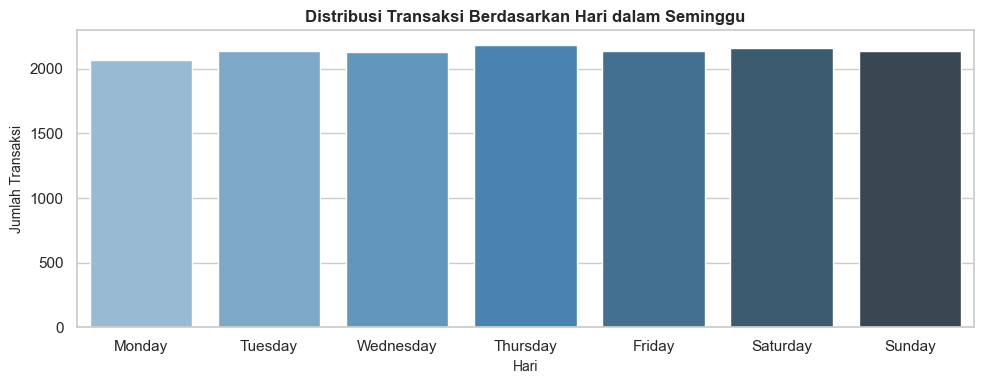

In [62]:
# Urutan hari dari Senin sampai Minggu
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Menghitung jumlah keranjang unik per hari
daily_tx = df.drop_duplicates('Transaction_ID')['Day_Name'].value_counts().reindex(days_order).reset_index()
daily_tx.columns = ['Day', 'Transaction_Count']

plt.figure(figsize=(10, 4))
sns.barplot(data=daily_tx, x='Day', y='Transaction_Count', hue ='Day', legend=False, palette='Blues_d')
plt.title('Distribusi Transaksi Berdasarkan Hari dalam Seminggu', fontsize=12, fontweight='bold')
plt.xlabel('Hari', fontsize=10)
plt.ylabel('Jumlah Transaksi', fontsize=10)
plt.tight_layout()
plt.show()

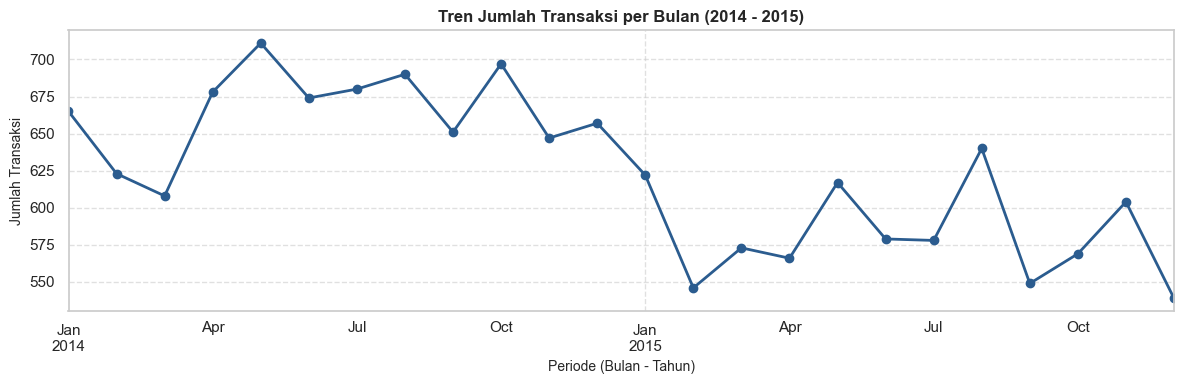

In [63]:
# Mengelompokkan transaksi per periode bulan-tahun
monthly_tx = df.drop_duplicates('Transaction_ID').groupby(df['Date'].dt.to_period('M')).size()

plt.figure(figsize=(12, 4))
monthly_tx.plot(kind='line', marker='o', color='#2b5c8f', linewidth=2)
plt.title('Tren Jumlah Transaksi per Bulan (2014 - 2015)', fontsize=12, fontweight='bold')
plt.xlabel('Periode (Bulan - Tahun)', fontsize=10)
plt.ylabel('Jumlah Transaksi', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Interpretasi & Insight Pola Waktu Belanja:

Berdasarkan visualisasi distribusi transaksi harian dan tren bulanan, diperoleh temuan strategis:

1. **Stabilitas Kunjungan Harian (Day of Week):**
   - Jumlah transaksi per hari relatif stabil merata sepanjang minggu (berkisar antara **2.067 s/d 2.188 transaksi per hari**).
   - Aktivitas belanja mencapai titik tertinggi (*peak days*) pada hari **Kamis (2.188 transaksi)** dan **Sabtu (2.161 transaksi)**, disusul Selasa dan Minggu.
   - Hal ini menunjukkan bahwa kebutuhan pokok groceries dibeli secara rutin harian, dengan sedikit peningkatan menjelang dan saat akhir pekan.

2. **Tren Transaksi Bulanan (Monthly Trend):**
   - Rata-rata transaksi berkisar antara **540 hingga 710 transaksi per bulan**.
   - Puncak transaksi tertinggi tercatat pada bulan **Mei dan Oktober**, yang menunjukkan kecenderungan volume yang stabil sepanjang tahun tanpa adanya volatilitas musiman ekstrem.

3. **Implikasi terhadap Strategi MBA:**
   - **Waktu Eksekusi Promosi Bundling:** Karena aliran pelanggan merata setiap hari, penataan rak (*product placement*) hasil aturan asosiasi relevan diterapkan secara permanen setiap hari.
   - **Kampanye Akhir Pekan:** Bundling produk dengan ukuran keranjang lebih besar ($\ge 3$ item) dapat diprioritaskan pada hari Kamis s/d Sabtu untuk memaksimalkan nilai transaksi per keranjang (*basket value*).

### Market Basket Analysis

In [64]:
# Persiapan Data Transaksi (One-Hot Encoding)

# Mengelompokkan item belanjaan per Transaction_ID
transactions = df.groupby('Transaction_ID')['itemDescription'].apply(list).tolist()

# Inisialisasi TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_basket = pd.DataFrame(te_ary, columns=te.columns_)
print(f"Dimensi Matriks Keranjang: {df_basket.shape[0]} transaksi x {df_basket.shape[1]} produk unik")

Dimensi Matriks Keranjang: 14963 transaksi x 167 produk unik


In [65]:
# Frequent Itemsets dengan Apriori
frequent_itemsets = apriori(df_basket, min_support=0.002, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
print(f"Total Frequent Itemsets yang ditemukan: {len(frequent_itemsets)}")
print(f"Rincian panjang itemset:\n{frequent_itemsets['length'].value_counts()}")

Total Frequent Itemsets yang ditemukan: 330
Rincian panjang itemset:
length
2    204
1    126
Name: count, dtype: int64


In [66]:
frequent_itemsets.sort_values('support',ascending=False).head(10)

,support,itemsets,length
123,0.157923,(whole milk),1
77,0.122101,(other vegetables),1
92,0.110005,(rolls/buns),1
103,0.097106,(soda),1
124,0.085879,(yogurt),1
93,0.069572,(root vegetables),1
115,0.067767,(tropical fruit),1
5,0.060683,(bottled water),1
98,0.060349,(sausage),1
22,0.053131,(citrus fruit),1


In [67]:
#Pembentukan Association Rules

# Filter aturan dengan Lift > 1.0 (korelasi positif)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)

# Konversi frozenset ke string agar mudah dibaca dan disimpan
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

# Urutkan berdasarkan Lift tertinggi
rules_sorted = rules.sort_values(by='lift', ascending=False).reset_index(drop=True)
print(f"Jumlah Aturan Asosiasi dengan Lift > 1: {len(rules_sorted)}")
rules_sorted[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']]

Jumlah Aturan Asosiasi dengan Lift > 1: 36


,antecedents_str,consequents_str,support,confidence,lift
0,curd,sausage,0.002941,0.087302,1.446615
1,sausage,curd,0.002941,0.048726,1.446615
2,brown bread,canned beer,0.002406,0.063943,1.362937
3,canned beer,brown bread,0.002406,0.051282,1.362937
4,sausage,frozen vegetables,0.002072,0.034330,1.225966
5,frozen vegetables,sausage,0.002072,0.073986,1.225966
6,bottled beer,sausage,0.003342,0.073746,1.222000
7,sausage,bottled beer,0.003342,0.055371,1.222000
8,frankfurter,other vegetables,0.005146,0.136283,1.116150
9,other vegetables,frankfurter,0.005146,0.042146,1.116150


In [68]:
# Filter aturan tanpa batas Lift minimal untuk melihat seluruh relasi whole milk
all_rules = association_rules(frequent_itemsets, metric="support", min_threshold=0.002)
all_rules['antecedents_str'] = all_rules['antecedents'].apply(lambda x: ', '.join(list(x)))
all_rules['consequents_str'] = all_rules['consequents'].apply(lambda x: ', '.join(list(x)))

# Filter khusus yang melibatkan whole milk
wm_rules = all_rules[
    (all_rules['antecedents_str'] == 'whole milk') | 
    (all_rules['consequents_str'] == 'whole milk')
]

# Urutkan berdasarkan Lift tertinggi 
top_wm_by_support = wm_rules.sort_values(by='lift', ascending=False)[
    ['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']
].head(10)

top_wm_by_support

,antecedents_str,consequents_str,support,confidence,lift
220,ham,whole milk,0.002740,0.160156,1.014142
221,whole milk,ham,0.002740,0.017351,1.014142
26,bottled beer,whole milk,0.007151,0.157817,0.999330
27,whole milk,bottled beer,0.007151,0.045281,0.999330
84,candy,whole milk,0.002139,0.148837,0.942468
85,whole milk,candy,0.002139,0.013542,0.942468
368,sausage,whole milk,0.008955,0.148394,0.939663
369,whole milk,sausage,0.008955,0.056708,0.939663
260,onions,whole milk,0.002941,0.145215,0.919528
261,whole milk,onions,0.002941,0.018620,0.919528


In [69]:
# Filter aturan tanpa batas Lift minimal untuk melihat seluruh relasi other vegetables
all_rules = association_rules(frequent_itemsets, metric="support", min_threshold=0.002)
all_rules['antecedents_str'] = all_rules['antecedents'].apply(lambda x: ', '.join(list(x)))
all_rules['consequents_str'] = all_rules['consequents'].apply(lambda x: ', '.join(list(x)))

# Filter khusus yang melibatkan other vegetables
ov_rules = all_rules[
    (all_rules['antecedents_str'] == 'other vegetables') | 
    (all_rules['consequents_str'] == 'other vegetables')
]

# Urutkan berdasarkan Lift tertinggi
top_ov_by_lift = ov_rules.sort_values(by='lift', ascending=False)[
    ['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']
].head(10)

top_ov_by_lift

,antecedents_str,consequents_str,support,confidence,lift
181,frankfurter,other vegetables,0.005146,0.136283,1.116150
180,other vegetables,frankfurter,0.005146,0.042146,1.116150
192,frozen meals,other vegetables,0.002139,0.127490,1.044134
193,other vegetables,frozen meals,0.002139,0.017515,1.044134
238,other vegetables,meat,0.002139,0.017515,1.039991
239,meat,other vegetables,0.002139,0.126984,1.039991
7,berries,other vegetables,0.002673,0.122699,1.004899
6,other vegetables,berries,0.002673,0.021894,1.004899
272,other vegetables,salty snack,0.002205,0.018062,0.961807
273,salty snack,other vegetables,0.002205,0.117438,0.961807


#### Interpretasi & Temuan Market Basket Analysis

Dari total 14.963 transaksi keranjang belanja yang dianalisis menggunakan algoritma *Apriori (min_support = 0.002, min_lift = 1.0), diperoleh 36 aturan asosiasi yang bermakna. Berikut adalah temuan strategisnya:

1. **Top Association Rules (Afinitas / Korelasi Belanja Terkuat):**
   - Curd <-> Sausage (Lift = 1.45, Support = 0.29%, Confidence = 8.73%):
     Pelanggan yang membeli curd memiliki kecenderungan **1,45 kali lipat lebih tinggi** untuk membeli sosis dibanding rata-rata pelanggan umum di toko.
   - Brown Bread <-> Canned Beer (Lift = 1.36, Support = 0.24%, Confidence = 6.39%)
   - Frozen Vegetables <-> Sausage (Lift = 1.23, Support = 0.21%, Confidence = 7.40%)
   - Bottled Beer <-> Sausage (Lift = 1.22, Support = 0.33%, Confidence = 7.37%)
     
2. **Perilaku Produk Pokok Terlaris (Whole Milk & Other Vegetables):**
   - Berdasarkan hasil filter mendalam pada produk terlaris toko (whole milk dan other vegetables), hampir seluruh kombinasi produk ini menghasilkan **Lift <= 1.0** (misal whole milk <-> other vegetables memiliki Lift = 0.77).
   - **Insight:** Kedua produk ini berfungsi sebagai **Independent Staple Goods** (barang pokok mandiri). Pelanggan datang ke toko memang bertujuan membeli susu atau sayuran dari rumah, bukan karena terpicu secara impulsif setelah melihat produk lain. Tingginya frekuensi kemunculan bersama mereka murni didorong oleh tingginya volume dasar masing-masing produk (baseline support), bukan karena tarikan afinitas antar-produk.


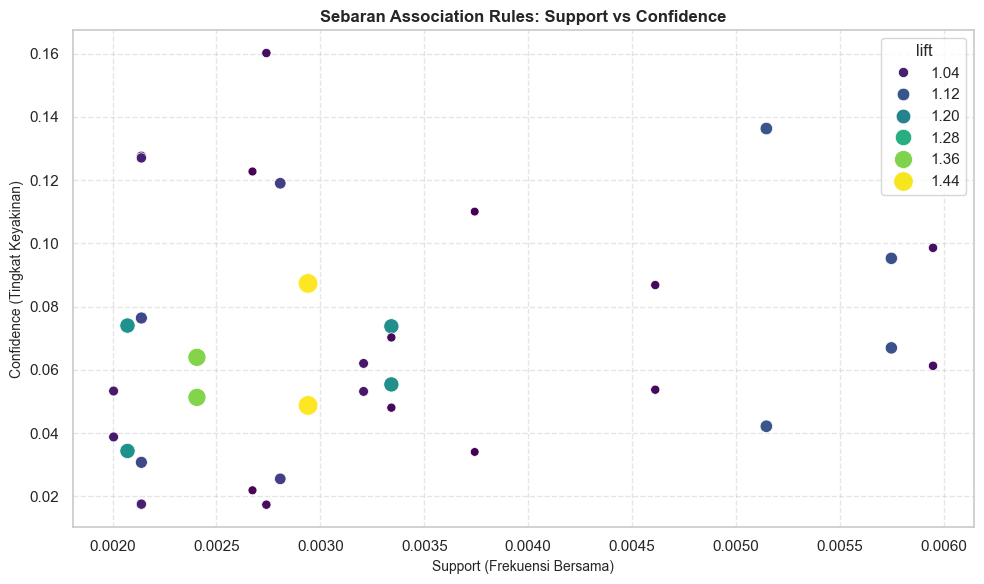

In [70]:
# Visualisasi Scatter Plot: Support vs Confidence (Hue = Lift)
plt.figure(figsize=(10, 6))
scatter = sns.scatterplot(
    data=rules_sorted,
    x='support',
    y='confidence',
    hue='lift',
    size='lift',
    sizes=(40, 200),
    palette='viridis'
)
plt.title('Sebaran Association Rules: Support vs Confidence', fontsize=12, fontweight='bold')
plt.xlabel('Support (Frekuensi Bersama)', fontsize=10)
plt.ylabel('Confidence (Tingkat Keyakinan)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


#### Interpretasi Sebaran Metrik & Rekomendasi Strategis Bisnis

Berdasarkan visualisasi scatter plot sebaran metrik *Support vs Confidence (Warna/Ukuran = Lift)* dan seluruh temuan analisis sebelumnya, diperoleh kesimpulan serta rekomendasi terapan berikut:

##### Karakteristik Sebaran Aturan (Scatter Plot):
- **Trade-off Support vs Confidence:** Aturan dengan *Support* lebih tinggi cenderung memiliki *Confidence* moderat. Tidak ada aturan dengan *Support* tinggi sekaligus *Confidence* ekstrem (>50%), yang menegaskan tingginya keragaman (*diversity*) keranjang belanja di toko groceries.
- **Konsentrasi High-Lift Rules:** Aturan-aturan dengan nilai Lift tertinggi (warna hijau kekuningan / titik berukuran besar) terkonsentrasi pada rentang Support $0.002 - 0.0035$ dan Confidence $5\% - 9\%$. Area inilah yang menjadi fokus utama strategi *cross-selling* dan *bundling*.

### 4. Ekspor Data untuk Dashboard Tableau

Tahap ini mengekspor dua dataset hasil pembersihan dan pemodelan agar siap digunakan sebagai sumber data pembuatan dashboard interaktif di Tableau:
1. cleaned_groceries.csv: Data transaksi pelanggan yang telah bersih dan tambahan dengan fitur waktu (Day_Name, Month, Year) serta ukuran keranjang (Basket_Size).
2. association_rules.csv: Daftar 36 aturan asosiasi terbaik hasil pemodelan Apriori (Lift > 1.0) yang memuat metrik Support, Confidence, dan Lift untuk analisis afinitas produk.


In [71]:
# 1. Ekspor dataset transaksi bersih untuk analisis overview, tren waktu, dan pelanggan di Tableau
df.to_csv('cleaned_groceries.csv', index=False)
print(f"Dataset transaksi bersih berhasil diekspor ke 'cleaned_groceries.csv' ({df.shape[0]:,} baris x {df.shape[1]} kolom).")

# 2. Ekspor hasil aturan asosiasi terbaik (Lift > 1) untuk analisis afinitas produk di Tableau
rules_sorted.to_csv('association_rules.csv', index=False)
print(f"Dataset aturan asosiasi berhasil diekspor ke 'association_rules.csv' ({rules_sorted.shape[0]} aturan).")


Dataset transaksi bersih berhasil diekspor ke 'cleaned_groceries.csv' (38,006 baris x 8 kolom).
Dataset aturan asosiasi berhasil diekspor ke 'association_rules.csv' (36 aturan).


### 4. Kesimpulan Akhir & Rekomendasi Bisnis Strategis

Berdasarkan integrasi temuan dari tahap **Exploratory Data Analysis (EDA)** dan **Association Rule Mining (Apriori)**, dirumuskan 2 pilar rekomendasi strategis untuk meningkatkan kinerja penjualan toko:

---

#### 1. Strategi Penataan Tata Letak Rak Toko (*Store Layout & Shelf Placement*)
* **Penempatan Bersilangan (*Cross-Category Proximity*):**
  - Pasangan produk dengan *Lift* tinggi seperti **curd (keju dadih) dan sausage (sosis)** (Lift = 1,45) sebaiknya ditempatkan di lemari pendingin (*chiller*) yang bersebelahan atau menggunakan *end-cap display* bersama.
  - Letakkan rak **brown bread** berdekatan dengan lorong minuman **canned beer / bottled beer** (Lift = 1,36) untuk mendorong pembelian spontan (*impulse buying*) bagi konsumen yang mencari camilan pendamping bir.
  - Tempatkan produk daging olahan (**frankfurter**) dekat dengan area sayur segar (**other vegetables**) (Lift = 1,12) untuk mempermudah konsumen yang berbelanja bahan makan malam.
* **Optimalisasi Alur Belanja (*Grid Traffic Flow*):**
  - Pertahankan penempatan produk jangkar (**whole milk** dengan penetrasi 15,8%) di bagian paling belakang toko, sehingga konsumen harus melintasi lorong produk olahan (sosis, keju, roti) sebelum mencapai lemari susu.

---

#### 2. Strategi Promosi Paket Belanja (*Product Bundling & Cross-Selling*)
* **Paket "Quick Family Dinner":**
  - Paket bundling bahan makan praktis: **Frozen Vegetables + Sausage / Frankfurter** untuk menyasar keluarga sibuk yang membutuhkan menu cepat saji.
* **Kupon Silang Bersyarat (*Conditional Cross-Coupons*):**
  - Konsumen yang membeli produk pemicu utama (misal: *Curd*) diberikan voucer kasir untuk potongan harga produk pasangan (*Sausage*) pada transaksi berikutnya.
